# Agentic AI-Based Dynamic Tariff Optimization for EV Charging Networks

**Open Project 2026 - Society of Business**



*  **ACN-Data**: 16,000+ workplace charging sessions (Caltech/JPL)
*   **UrbanEV (ST-EVCDP)**: 24,798 charging piles at 5-minute intervals(Shenzhen)



### Notebook Structure


1.   Setup and Data Loading
2.   Data Preprocessing and Feature Engineering

1.   Exploratory Data Analysis (EDA)
2.   Agent 1 - Demand Prediction Agent

1.   Agent 2 - Tariff Pricing Agent
2.   Agent 3 - Monitoring and Learning Agent

1.   Evaluation Summary and CSV Outputs










## 1. Setup and Data Loading

In [146]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
warnings.filterwarnings('ignore')

# For consistent plot style
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 100

In [147]:
from google.colab import drive
drive.mount('/content/drive')

data_path = '/content/drive/MyDrive/EV_Project/data'
os.makedirs('/content/drive/MyDrive/EV_Project/outputs', exist_ok=True)
output_path = '/content/drive/MyDrive/EV_Project/outputs'

print("Files available:", os.listdir(data_path))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Files available: ['acndata_sessions.json.xlsx', 'information.csv', 'adj.csv', 'stations.csv', 'distance.csv', 'time.csv', 'occupancy.csv', 'price.csv', 'duration.csv', 'volume.csv']


## 2. Data Preprocessing and Feature Engineering

### 2.1 ACN-Data (Caltech/JPL Workplace Charging Sessions)

In [148]:
# Load ACN dataset
acn_df = pd.read_excel(f'{data_path}/acndata_sessions.json.xlsx',dtype={'clusterID':str,'siteID':str,'userID':str,'userID.1':str})
print("Shape:",acn_df.shape)
acn_df.head()

Shape: (16304, 27)


,_meta,end,min_kWh,site,start,_items,_id,clusterID,connectionTime,disconnectTime,...,userID,userInputs,WhPerMile,kWhRequested,milesRequested,minutesAvailable,modifiedAt,paymentRequired,requestedDeparture,userID.1
0,NaN,NaN,NaN,caltech,NaN,NaN,5bc90cb9f9af8b0d7fe77cd2,0039,"Wed, 25 Apr 2018 11:08:04 GMT","Wed, 25 Apr 2018 13:20:10 GMT",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,5bc90cb9f9af8b0d7fe77cd3,0039,"Wed, 25 Apr 2018 13:45:10 GMT","Thu, 26 Apr 2018 00:56:16 GMT",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,5bc90cb9f9af8b0d7fe77cd4,0039,"Wed, 25 Apr 2018 13:45:50 GMT","Wed, 25 Apr 2018 23:04:45 GMT",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,5bc90cb9f9af8b0d7fe77cd5,0039,"Wed, 25 Apr 2018 14:37:06 GMT","Wed, 25 Apr 2018 23:55:34 GMT",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,5bc90cb9f9af8b0d7fe77cd6,0039,"Wed, 25 Apr 2018 14:40:34 GMT","Wed, 25 Apr 2018 23:03:12 GMT",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [149]:
acn_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16304 entries, 0 to 16303
Data columns (total 27 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   _meta               0 non-null      float64
 1   end                 0 non-null      float64
 2   min_kWh             0 non-null      float64
 3   site                1 non-null      object 
 4   start               0 non-null      float64
 5   _items              0 non-null      float64
 6   _id                 14999 non-null  object 
 7   clusterID           14999 non-null  object 
 8   connectionTime      14999 non-null  object 
 9   disconnectTime      14999 non-null  object 
 10  doneChargingTime    14991 non-null  object 
 11  kWhDelivered        14999 non-null  float64
 12  sessionID           14999 non-null  object 
 13  siteID              14999 non-null  object 
 14  spaceID             14999 non-null  object 
 15  stationID           14999 non-null  object 
 16  time

In [150]:
# Missing value summary
missing = acn_df.isna().sum()
missing = missing[missing>0].sort_values(ascending=False)
missing

,0
_meta,16304
end,16304
min_kWh,16304
start,16304
_items,16304
userInputs,16304
site,16303
userID,14072
paymentRequired,12767
modifiedAt,12767


**Missing value strategy (ACN-Data):**

After examining the missing values, six columns (_meta, start, end, _items, userInputs, and min_kWh) were removed because they contained no data at all.

Several other columns, including userID, WhPerMile, kWhRequested, milesRequested, minutesAvailable, modifiedAt, paymentRequired, requestedDeparture, and userID.1, had a high proportion of missing values (around 77%). These were retained since they represent optional user-provided information and were not directly used in the modelling process.

The key charging-related variables, such as energy delivered (kWhDelivered), session duration (sessionDurationHours), and timestamp fields, contained no missing values once the completely empty columns were removed.

In [151]:
# Drop fully empty columns
drop_cols = ['_meta','start','end','_items','userInputs','min_kWh']
acn_df = acn_df.drop(columns=drop_cols)

# Parse timestamps
time_cols = ['connectionTime','disconnectTime','doneChargingTime']
for col in time_cols:
  acn_df[col] = pd.to_datetime(acn_df[col])

# Session duration
acn_df['sessionDurationHours'] = (acn_df['disconnectTime']-acn_df['connectionTime']).dt.total_seconds()/3600

# Remove outliers: session > 24 hours (data errors)
before = len(acn_df)
acn_df = acn_df[acn_df['sessionDurationHours'] <= 24].copy()
print(f"Rows removed: {before-len(acn_df)} ({(before-len(acn_df))*100/before}%)")
print("Final shape:",acn_df.shape)

Rows removed: 1456 (8.930323846908735%)
Final shape: (14848, 22)


In [152]:
# Temporal Feature Extraction
week_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']

acn_df['hour'] = acn_df['connectionTime'].dt.hour
acn_df['weekday'] = acn_df['connectionTime'].dt.day_name()
acn_df['isweekend'] = acn_df['weekday'].isin(['Saturday','Sunday'])
acn_df['month'] = acn_df['connectionTime'].dt.month
acn_df['date'] = acn_df['connectionTime'].dt.date

# Creating additional features for analysis

# Utilization of charger assuming it is available throughout the day
acn_df["charger_utilization_rate"] = acn_df["sessionDurationHours"]/24

# Estimated revenue generated from each charging session
tariff_rate = 15    # Rs./kWh
acn_df["revenue_per_session"] = acn_df["kWhDelivered"]*tariff_rate

# Estimated electricity procurement cost
cost_rate = 8       # Rs./kWh
acn_df["energy_cost_per_session"] = acn_df["kWhDelivered"]*cost_rate

# Average charging power delivered during the session
acn_df['charging_rate_kw'] = acn_df['kWhDelivered']/acn_df['sessionDurationHours']

# Categorizing sessions based on the time of day
def get_time_period(hour):
    if 14 <= hour <= 16:
        return "Peak"
    elif 12 <= hour <= 20:
        return "Shoulder"
    else:
        return "Off-Peak"

acn_df['time_period'] = acn_df['hour'].apply(get_time_period)

acn_df[["sessionDurationHours","charger_utilization_rate","revenue_per_session","energy_cost_per_session","charging_rate_kw","time_period"]].describe()

,sessionDurationHours,charger_utilization_rate,revenue_per_session,energy_cost_per_session,charging_rate_kw
count,14848.000000,14848.000000,14848.000000,14848.000000,14848.000000
mean,5.495452,0.228977,134.141713,71.542247,2.509346
std,3.965116,0.165213,104.313119,55.633663,1.972876
min,0.087500,0.003646,7.515000,4.008000,0.040516
25%,2.007708,0.083655,59.790000,31.888000,0.979776
50%,4.695833,0.195660,111.262500,59.340000,1.807720
75%,8.674792,0.361450,197.970000,105.584000,3.470260
max,23.991389,0.999641,1040.595000,554.984000,23.482480


### 2.2 UrbanEV Dataset (ST-EVCDP - Shenzhen)

The ST-EVCDP dataset is split across multiple CSV files aligned on a shared timestamp index (5-minute intervals). We load, align and merge them into a single master dataframe.

In [153]:
# Load all UrbanEV files
price_df = pd.read_csv(f'{data_path}/price.csv')
volume_df = pd.read_csv(f'{data_path}/volume.csv')
occupancy_df = pd.read_csv(f'{data_path}/occupancy.csv')
duration_df = pd.read_csv(f'{data_path}/duration.csv')
time_df = pd.read_csv(f'{data_path}/time.csv')
stations_df = pd.read_csv(f'{data_path}/stations.csv')
information_df = pd.read_csv(f'{data_path}/information.csv')
distance_df = pd.read_csv(f'{data_path}/distance.csv')
adj_df = pd.read_csv(f'{data_path}/adj.csv')

print("Price shape:", price_df.shape)
print("Volume shape:", volume_df.shape)
print("Occupancy shape:", occupancy_df.shape)
print("Duration shape:", duration_df.shape)
print("Time shape:", time_df.shape)

Price shape: (8640, 248)
Volume shape: (8640, 248)
Occupancy shape: (8640, 248)
Duration shape: (8640, 248)
Time shape: (8640, 6)


In [154]:
# Building unified timestamp from time.csv
time_df['timestamp'] = pd.to_datetime(time_df[['year','month','day','hour','minute','second']])
time_df['weekday_name'] = time_df['timestamp'].dt.day_name()

# Verify 5-min intervals
gaps = time_df['timestamp'].diff().dropna().dt.total_seconds()/60
print("Interval stats:")
gaps.value_counts().head()

Interval stats:


,count
timestamp,
5.0,8639


In [155]:
# Converting each wide dataframe to long format, aligning on the shared timestamp
def wide_to_long(df,value_name):
  df = df.copy()
  df['timestamp'] = time_df['timestamp'].values
  return df.melt(id_vars='timestamp',var_name='node_id',value_name=value_name)

occupancy_long = wide_to_long(occupancy_df,'occupancy')
volume_long = wide_to_long(volume_df,'volume')
duration_long = wide_to_long(duration_df,'duration')
price_long = wide_to_long(price_df,'price')

master_df = occupancy_long.merge(volume_long,on=['timestamp','node_id']).merge(duration_long,on=['timestamp','node_id']).merge(price_long,on=['timestamp','node_id'])
master_df['node_id'] = master_df['node_id'].astype(int)
print("Master shape:",master_df.shape)
master_df.head()

Master shape: (2134080, 6)


,timestamp,node_id,occupancy,volume,duration,price
0,2022-06-19 00:00:00,102,12,2.858333,0.49,0.924
1,2022-06-19 00:05:00,102,12,4.375000,0.75,0.924
2,2022-06-19 00:10:00,102,12,4.375000,0.75,0.924
3,2022-06-19 00:15:00,102,12,4.375000,0.75,0.924
4,2022-06-19 00:20:00,102,12,4.375000,0.75,0.924


In [156]:
# Missing values in master_df
print("Missing values per column:")
master_df.isnull().sum()

Missing values per column:


,0
timestamp,0
node_id,0
occupancy,0
volume,0
duration,0
price,0


No missing values exist in the ST-EVCDP numeric files after the merge — confirmed above. The timestamp alignment is exact because all files share the same index order from time.csv.

In [157]:
# Temporal features
master_df['hour'] = master_df['timestamp'].dt.hour
master_df['day'] = master_df['timestamp'].dt.day
master_df['month'] = master_df['timestamp'].dt.month
master_df['weekday'] = master_df['timestamp'].dt.dayofweek
master_df['is_weekend'] = (master_df['weekday'] >=5).astype(int)
master_df['time_period'] = master_df['hour'].apply(get_time_period)

In [158]:
# Engineered Features

# Station max occupancy (from stations_df)
station_capacity = stations_df.set_index('station_id')['count'].to_dict()
master_df['station_capacity'] = master_df['node_id'].map(station_capacity)

# Charger Utilization Rate = occupancy/station capacity
master_df['charger_utilization_rate'] = (master_df['occupancy']/master_df['station_capacity'].clip(lower=1)).clip(0,1)

# Occupancy Density
master_df['occupancy_density'] = (master_df['occupancy']/(master_df['occupancy'].max()+1))

# Revenue per session
master_df['revenue'] = master_df['volume']*master_df['price']

# Queue length proxy = occupancy_density x duration
master_df['queue_proxy'] = master_df['occupancy_density']*master_df['duration']

# Duration per volume
master_df['duration_per_volume'] = master_df['duration']/(master_df['volume']+1)

# Congestion level labels (thresholds: surge>80%, discount<30%)
master_df['congestion_level'] = pd.cut(master_df['occupancy_density'],bins=[-0.01,0.3,0.8,1.01],labels=['Low','Medium','High'])

master_df[['charger_utilization_rate','occupancy_density','revenue','queue_proxy','congestion_level']].describe()

,charger_utilization_rate,occupancy_density,revenue,queue_proxy
count,2.134080e+06,2.134080e+06,2.134080e+06,2.134080e+06
mean,7.699707e-01,9.910427e-02,2.999742e+01,3.387309e-01
std,3.397654e-01,1.122161e-01,7.330484e+01,8.667466e-01
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,5.000000e-01,2.262443e-02,2.275000e+00,6.033182e-03
50%,1.000000e+00,5.882353e-02,6.808958e+00,4.562594e-02
75%,1.000000e+00,1.357466e-01,2.170000e+01,2.428356e-01
max,1.000000e+00,9.954751e-01,1.026874e+03,1.668100e+01


In [159]:
# Merge station information
master_df = master_df.merge(information_df, left_on='node_id',right_on='grid',how='left')
print("After merge with information_df:", master_df.shape)
master_df[['count','fast_count','slow_count','area','CBD','dynamic_pricing']].isna().sum()

After merge with information_df: (2134080, 29)


,0
count,0
fast_count,0
slow_count,0
area,0
CBD,0
dynamic_pricing,0


**Cross-dataset note:**

The ACN-Data and ST-EVCDP datasets come from different geographies (US vs. China) and different temporal scopes, so a row-level join is not meaningful.

They are analysed in parallel: ACN-Data informs session-level behaviour (duration, energy), while ST-EVCDP provides high-frequency demand, pricing and occupancy signals used in the ML agents.

## 3. Exploratory Data Analysis (EDA)

### 3.1 ACN-Data -- Session-Level Demand Patterns

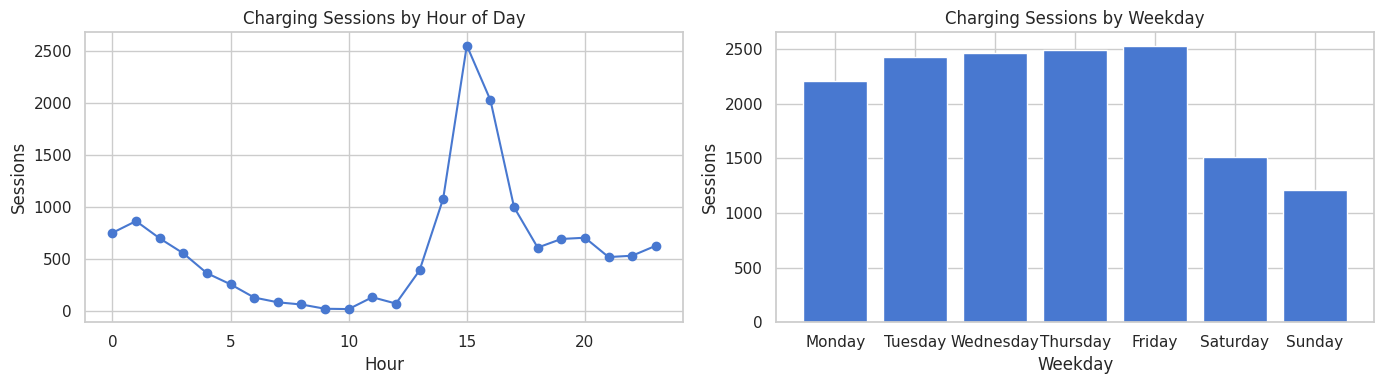

In [160]:
fig, axes = plt.subplots(1,2,figsize=(14,4))

# Hourly demand
hourly = acn_df['hour'].value_counts().sort_index()
axes[0].plot(hourly.index,hourly.values,marker='o')
axes[0].set_title('Charging Sessions by Hour of Day')
axes[0].set_xlabel('Hour')
axes[0].set_ylabel('Sessions')

# Weekday demand
wday = acn_df['weekday'].value_counts().reindex(week_order)
axes[1].bar(wday.index,wday.values)
axes[1].set_title('Charging Sessions by Weekday')
axes[1].set_xlabel('Weekday')
axes[1].set_ylabel('Sessions')

plt.tight_layout()
plt.show()

**Insight:**

Charging demand peaks in the afternoon (around 2–4 PM) and is consistently higher on weekdays than on weekends. Weekend usage, especially on Sunday, is substantially lower, indicating stronger weekday dependence.

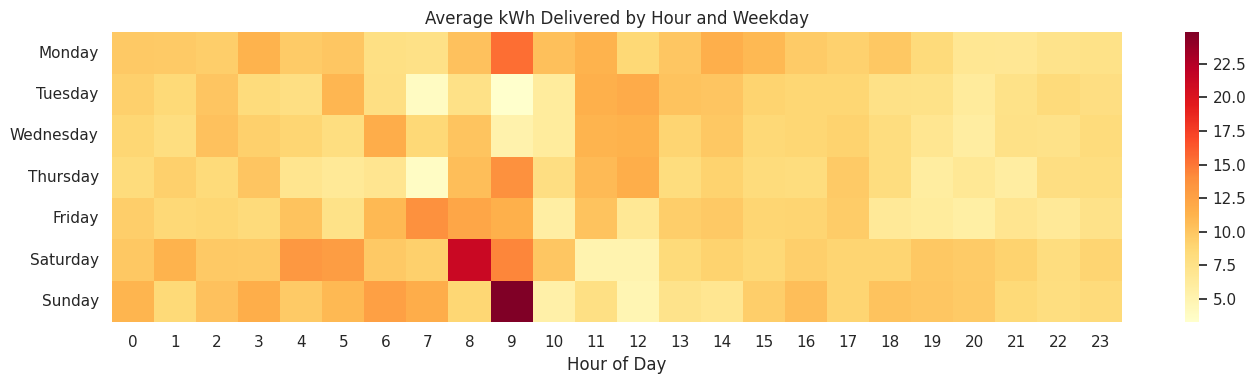

In [161]:
# Average energy delivered across different hours and weekdays

energy_by_time = acn_df.pivot_table(values='kWhDelivered',index='weekday',columns='hour',aggfunc='mean')
energy_by_time = energy_by_time.reindex(week_order)

plt.figure(figsize=(14,4))
sns.heatmap(energy_by_time, cmap='YlOrRd')
plt.title('Average kWh Delivered by Hour and Weekday')
plt.xlabel('Hour of Day')
plt.ylabel('')
plt.tight_layout()
plt.show()

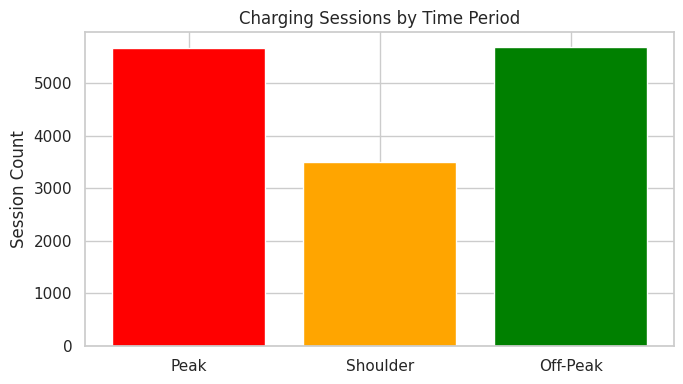


 Demand Volatility by Time Period:


,mean,std,cv
time_period,,,
Peak,9.198808,6.590173,0.716416
Shoulder,8.424662,6.451650,0.765805
Off-Peak,9.005672,7.563572,0.839868


In [162]:
# Number of sessions in each charging period
session_counts = (acn_df['time_period'].value_counts().reindex(['Peak','Shoulder','Off-Peak']))

plt.figure(figsize=(7,4))
plt.bar(session_counts.index,session_counts.values,color=['red','orange','green'])
plt.title('Charging Sessions by Time Period')
plt.ylabel("Session Count")
plt.tight_layout()
plt.show()

# Comparing variability in energy demand across periods
demand_stats = acn_df.groupby('time_period')['kWhDelivered'].agg(['mean','std']).reindex(['Peak','Shoulder','Off-Peak'])
demand_stats['cv'] = demand_stats['std']/demand_stats['mean']

print('\n Demand Volatility by Time Period:')
demand_stats

**Key finding:**

The coefficient of variation (CV) is highest during Off-Peak hours, indicating unstable, sporadic demand — exactly the regime where discount pricing can stimulate more predictable utilization.

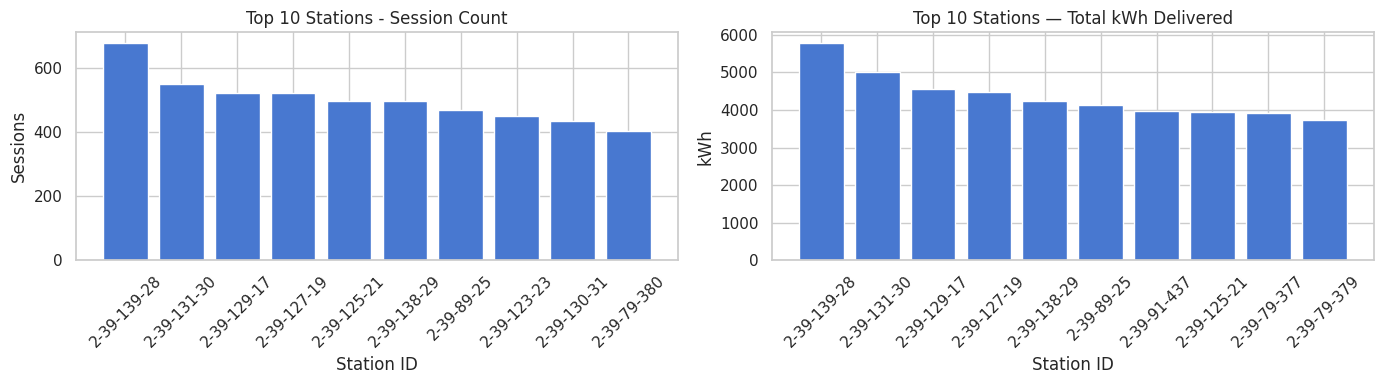

In [163]:
# Station level abalysis
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

top_sessions = acn_df['stationID'].value_counts().head(10)
axes[0].bar(top_sessions.index.astype(str),top_sessions.values)
axes[0].set_title('Top 10 Stations - Session Count')
axes[0].set_xlabel('Station ID')
axes[0].set_ylabel('Sessions')
axes[0].tick_params(axis='x', rotation=45)

top_energy = acn_df.groupby('stationID')['kWhDelivered'].sum().sort_values(ascending=False).head(10)
axes[1].bar(top_energy.index.astype(str), top_energy.values)
axes[1].set_title('Top 10 Stations — Total kWh Delivered')
axes[1].set_xlabel('Station ID')
axes[1].set_ylabel('kWh')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

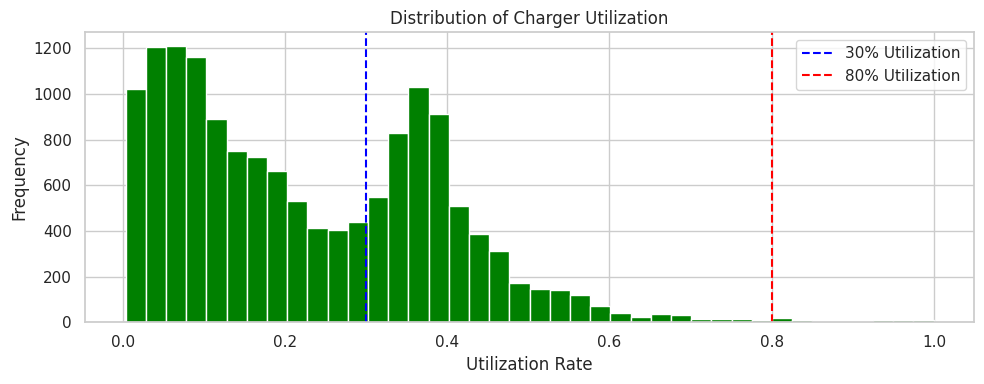

,charger_utilization_rate
count,14848.000000
mean,0.228977
std,0.165213
min,0.003646
25%,0.083655
50%,0.195660
75%,0.361450
max,0.999641


In [164]:
# Distribution of charger utilization levels
plt.figure(figsize=(10,4))
plt.hist(acn_df['charger_utilization_rate'],bins=40,color='green')
plt.axvline(x=0.3,color='blue',linestyle='--',label="30% Utilization")
plt.axvline(x=0.8,color='red',linestyle='--',label="80% Utilization")
plt.title('Distribution of Charger Utilization')
plt.xlabel('Utilization Rate')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()

acn_df['charger_utilization_rate'].describe()

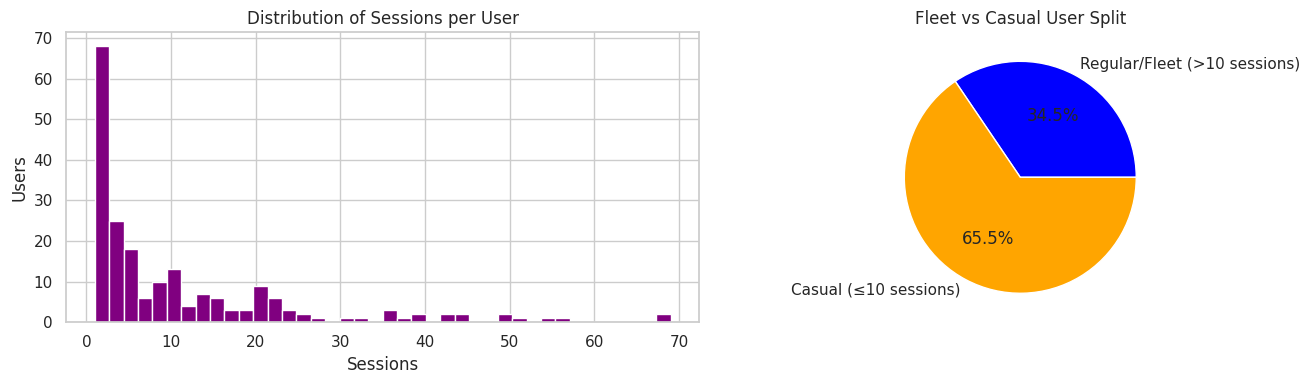

Regular/Fleet users: 70 | Casual users: 133


In [165]:
# User behaviour analysis
user_sessions = acn_df['userID'].value_counts().dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(user_sessions, bins=40, color='purple')
axes[0].set_title('Distribution of Sessions per User')
axes[0].set_xlabel('Sessions')
axes[0].set_ylabel('Users')

# Fleet vs public proxy: users with > 10 sessions = likely fleet/regular
regular_users = (user_sessions > 10).sum()
casual_users  = (user_sessions <= 10).sum()

axes[1].pie([regular_users, casual_users],labels=['Regular/Fleet (>10 sessions)', 'Casual (≤10 sessions)'],autopct='%1.1f%%', colors=['blue','orange'])
axes[1].set_title('Fleet vs Casual User Split')
plt.tight_layout()
plt.show()

print(f"Regular/Fleet users: {regular_users} | Casual users: {casual_users}")

### 3.2 UrbanEV (ST-EVCDP) - Temporal and Spatial Demand Patterns


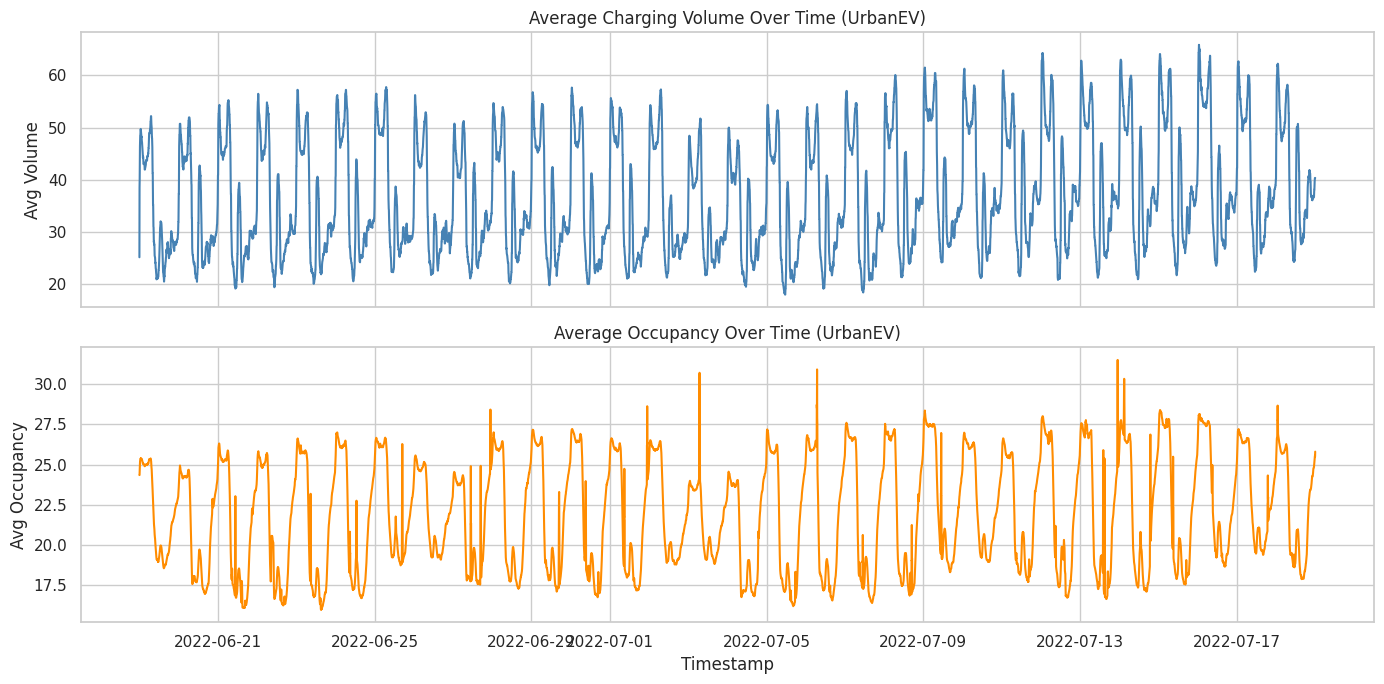

In [166]:
from pandas._libs.tslibs import timestamps
# Average volume and occupancy over time
avg_volume = volume_df.drop(columns='timestamp').mean(axis=1)
avg_occupancy = occupancy_df.drop(columns='timestamp').mean(axis=1)
timestamps = time_df['timestamp']

fig, axes = plt.subplots(2,1, figsize=(14,7), sharex=True)
axes[0].plot(timestamps,avg_volume,color='steelblue')
axes[0].set_title('Average Charging Volume Over Time (UrbanEV)')
axes[0].set_ylabel('Avg Volume')

axes[1].plot(timestamps,avg_occupancy,color='darkorange')
axes[1].set_title('Average Occupancy Over Time (UrbanEV)')
axes[1].set_ylabel('Avg Occupancy')
axes[1].set_xlabel('Timestamp')

plt.tight_layout()
plt.show()

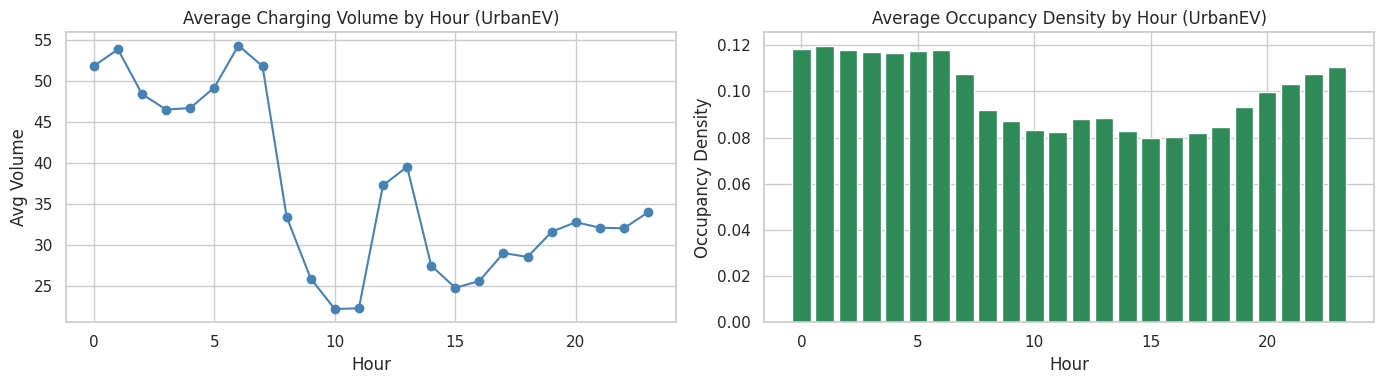

In [167]:
hourly_vol = master_df.groupby('hour')['volume'].mean()
hourly_occ = master_df.groupby('hour')['occupancy_density'].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Charging volume
axes[0].plot(hourly_vol.index, hourly_vol.values,
             marker='o', color='steelblue')
axes[0].set_title('Average Charging Volume by Hour (UrbanEV)')
axes[0].set_xlabel('Hour')
axes[0].set_ylabel('Avg Volume')

# Occupancy density
axes[1].bar(hourly_occ.index, hourly_occ.values, color='seagreen')
axes[1].set_title('Average Occupancy Density by Hour (UrbanEV)')
axes[1].set_xlabel('Hour')
axes[1].set_ylabel('Occupancy Density')

plt.tight_layout()
plt.show()

In [168]:
# Volatility across time periods (UrbanEV)
vol_period = master_df.groupby('time_period')['volume'].agg(['mean','std']).reindex(['Peak','Shoulder','Off-Peak'])
vol_period['cv'] = vol_period['std']/vol_period['mean']
print('UrbanEV Demand Volatility by Time Period:')
vol_period

UrbanEV Demand Volatility by Time Period:


,mean,std,cv
time_period,,,
Peak,25.926839,62.730459,2.419518
Shoulder,33.086765,86.810017,2.623708
Off-Peak,40.265443,113.000443,2.806388


In [169]:
# Weekday vs Weekend
wkd_vol = master_df.groupby('is_weekend')['volume'].mean()
print("Average volume - Weekday vs Weekend:")
wkd_vol.rename({0:'Weekday',1:'Weekend'})

Average volume - Weekday vs Weekend:


,volume
is_weekend,
Weekday,36.498925
Weekend,37.097333


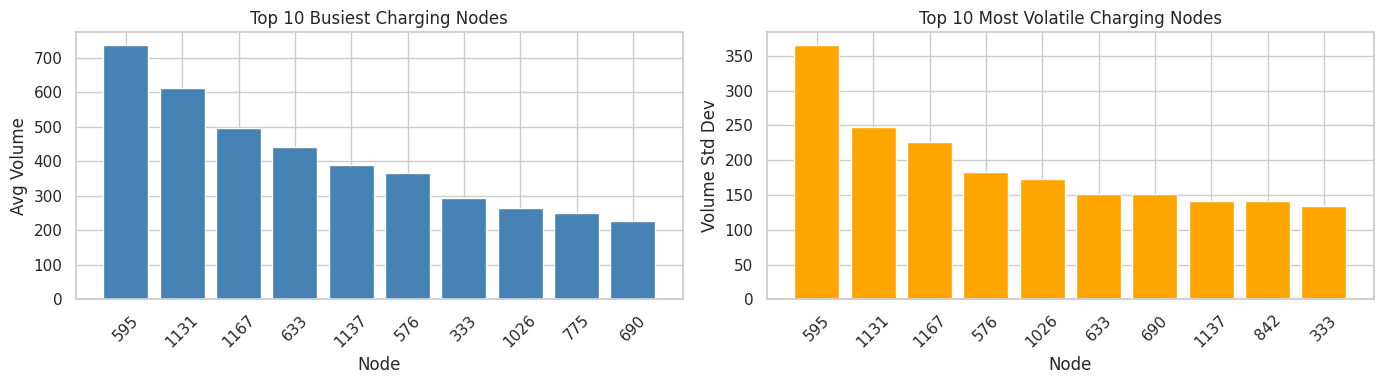

In [170]:
# Top busiest and most volatile nodes
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

top_busy = volume_df.drop(columns='timestamp').mean().sort_values(ascending=False).head(10)
axes[0].bar(top_busy.index.astype(str),top_busy.values,color='steelblue')
axes[0].set_title('Top 10 Busiest Charging Nodes')
axes[0].set_xlabel('Node')
axes[0].set_ylabel('Avg Volume')
axes[0].tick_params(axis='x',rotation=45)

top_vol = volume_df.drop(columns='timestamp').std().sort_values(ascending=False).head(10)
axes[1].bar(top_vol.index.astype(str),top_vol.values,color='orange')
axes[1].set_title('Top 10 Most Volatile Charging Nodes')
axes[1].set_xlabel('Node')
axes[1].set_ylabel('Volume Std Dev')
axes[1].tick_params(axis='x',rotation=45)

plt.tight_layout()
plt.show()

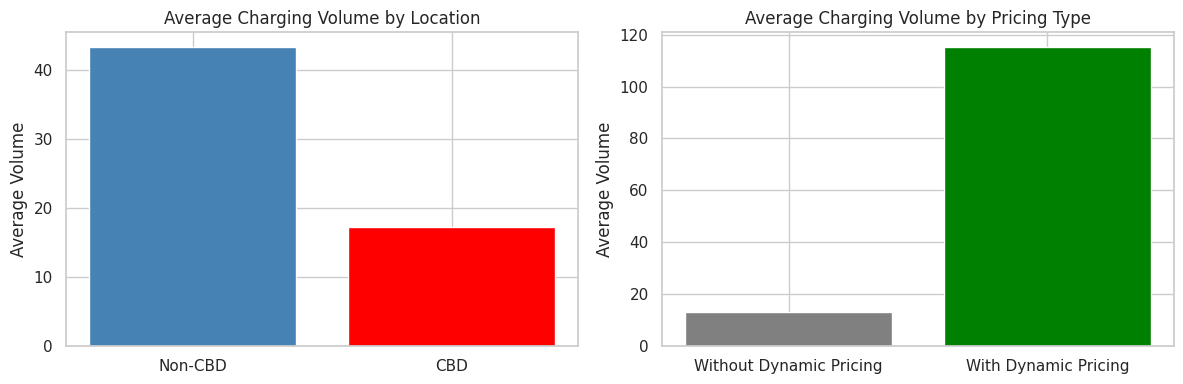

In [171]:
# CBD vs Non-CBD and dynamic pricing analysis
fig,axes = plt.subplots(1,2,figsize=(12, 4))

if 'CBD' in master_df.columns:
  cbd_avg = master_df.groupby('CBD')['volume'].mean().rename({0:'Non-CBD',1:'CBD'})

  axes[0].bar(cbd_avg.index,cbd_avg.values,color=['steelblue','red'])
  axes[0].set_title('Average Charging Volume by Location')
  axes[0].set_ylabel('Average Volume')

if 'dynamic_pricing' in master_df.columns:
  pricing_avg = master_df.groupby('dynamic_pricing')['volume'].mean().rename({0:'Without Dynamic Pricing',1:'With Dynamic Pricing'})

  axes[1].bar(pricing_avg.index,pricing_avg.values,color=['gray','green'])
  axes[1].set_title('Average Charging Volume by Pricing Type')
  axes[1].set_ylabel('Average Volume')

plt.tight_layout()
plt.show()

## 4. Agent 1 - Demand Prediction Agent
**Goal:** Predict future charging demand (volume) and congestion probability at each station using historical session features.

**Models trained:** Random Forest, Extra Trees, Gradient Boosting, XGBoost, LightGBM, Ridge Regression (regression) and Random Forest, Extra Trees, Gradient Boosting, XGBoost, LightGBM, Logistic Regression (classification).

All models are trained on identical features and splits; the best performer (by R² / Accuracy) is carried forward.

**Outputs:**
- Predicted charging load (volume)
- Predicted utilization rate
- Congestion probability (Low / Medium / High)

In [172]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor,RandomForestClassifier,GradientBoostingRegressor,GradientBoostingClassifier,ExtraTreesClassifier,ExtraTreesRegressor
from sklearn.linear_model import Ridge,LogisticRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score,accuracy_score,classification_report,ConfusionMatrixDisplay
import xgboost as xgb
import lightgbm as lgb

### 4.1 Demand Load Prediction

In [173]:
# Sample for computational efficiency
sample_df = master_df.dropna(subset=['fast_count','slow_count','CBD','dynamic_pricing','area']).sample(n=min(200000, len(master_df)), random_state=42)
feature_cols = ['occupancy', 'duration', 'price','hour', 'weekday', 'month', 'is_weekend','fast_count', 'slow_count', 'CBD', 'dynamic_pricing', 'area']

X_reg = sample_df[feature_cols]
y_reg = sample_df['volume']
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

print(f"Train: {X_train_r.shape} | Test: {X_test_r.shape}")

Train: (160000, 12) | Test: (40000, 12)


In [174]:
# Multi-Model Regression Training and Comparison
regressors = {'Random Forest':RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
              'Extra Trees':ExtraTreesRegressor(n_estimators=100, random_state=42, n_jobs=-1),
              'Gradient Boosting':GradientBoostingRegressor(n_estimators=100, random_state=42, max_depth=5),
              'XGBoost':xgb.XGBRegressor(n_estimators=100, random_state=42, n_jobs=-1, verbosity=0),
              'LightGBM':lgb.LGBMRegressor(n_estimators=100, random_state=42, n_jobs=-1, verbose=-1),
              'Ridge Regression':Ridge(alpha=1.0)}

reg_results = {}
trained_regressors = {}

for name,model in regressors.items():
  model.fit(X_train_r,y_train_r)
  predictions = model.predict(X_test_r)
  mae = mean_absolute_error(y_test_r,predictions)
  rmse = mean_squared_error(y_test_r,predictions)**0.5
  r2 = r2_score(y_test_r,predictions)

  reg_results[name] = {'MAE':mae,'RMSE':rmse,'R2':r2,'Predictions':predictions}
  trained_regressors[name] = model

  print(f"{name} MAE={mae} RMSE={rmse} R2={r2}")

best_reg_name = max(reg_results, key=lambda x:reg_results[x]['R2'])
preds_r = reg_results[best_reg_name]['Predictions']
rf_regressor = trained_regressors[best_reg_name]

mae_r = reg_results[best_reg_name]["MAE"]
rmse_r = reg_results[best_reg_name]['RMSE']
r2_r = reg_results[best_reg_name]['R2']
print(f"\nBest regressor: {best_reg_name} (R2={r2_r})")

Random Forest MAE=2.1927227250007153 RMSE=8.569439495562767 R2=0.9928079750961685
Extra Trees MAE=1.9942585790782819 RMSE=8.076667929517534 R2=0.9936113248818412
Gradient Boosting MAE=4.542685627981956 RMSE=12.604174133214661 R2=0.9844412343978112
XGBoost MAE=3.2845086106062955 RMSE=9.823462009890397 R2=0.990549049492601
LightGBM MAE=3.949550772721431 RMSE=10.8424415494356 R2=0.9884866812571681
Ridge Regression MAE=29.430752151262613 RMSE=53.11136289609679 R2=0.7237379430809638

Best regressor: Extra Trees (R2=0.9936113248818412)


### 4.1a Regression Model Comparison


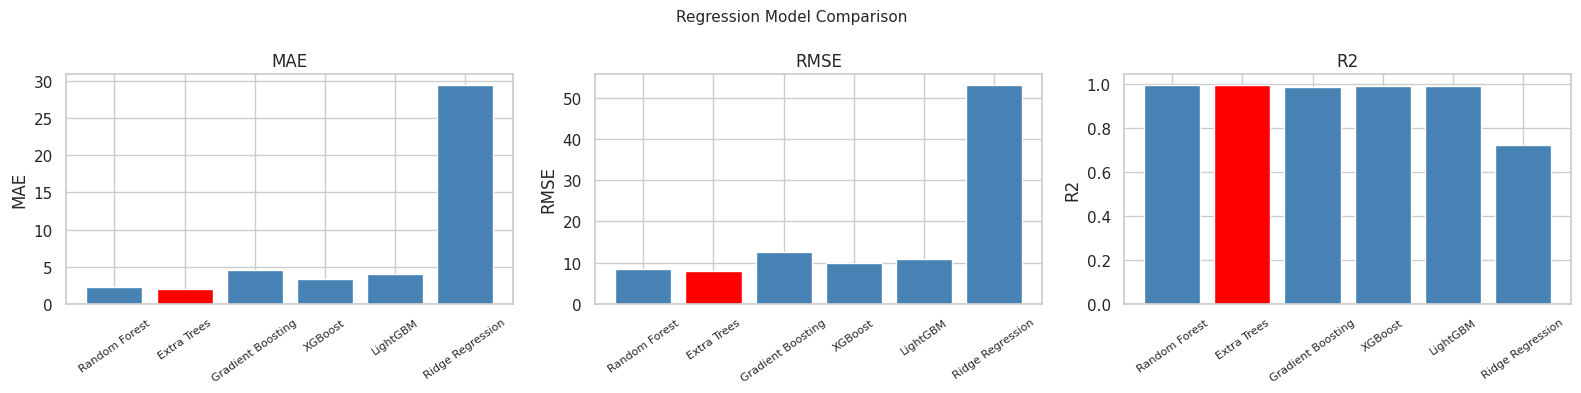


Model Performance Summary:
                         MAE       RMSE        R2
Random Forest       2.192723   8.569439  0.992808
Extra Trees         1.994259   8.076668  0.993611
Gradient Boosting   4.542686  12.604174  0.984441
XGBoost             3.284509   9.823462  0.990549
LightGBM            3.949551  10.842442  0.988487
Ridge Regression   29.430752  53.111363  0.723738


In [175]:
reg_df = pd.DataFrame(reg_results).T.drop(columns="Predictions").astype(float)
fig,axes = plt.subplots(1,3,figsize=(16,4))
bar_colors = ['red' if model==best_reg_name else 'steelblue' for model in reg_df.index]

for ax,metric in zip(axes,['MAE','RMSE','R2']):
  ax.bar(reg_df.index,reg_df[metric],color=bar_colors)
  ax.set_title(metric)
  ax.set_ylabel(metric)
  ax.tick_params(axis='x', rotation=35, labelsize=8)

plt.suptitle('Regression Model Comparison', fontsize=11)
plt.tight_layout()
plt.show()

print("\nModel Performance Summary:")
print(reg_df[['MAE', 'RMSE', 'R2']].to_string())

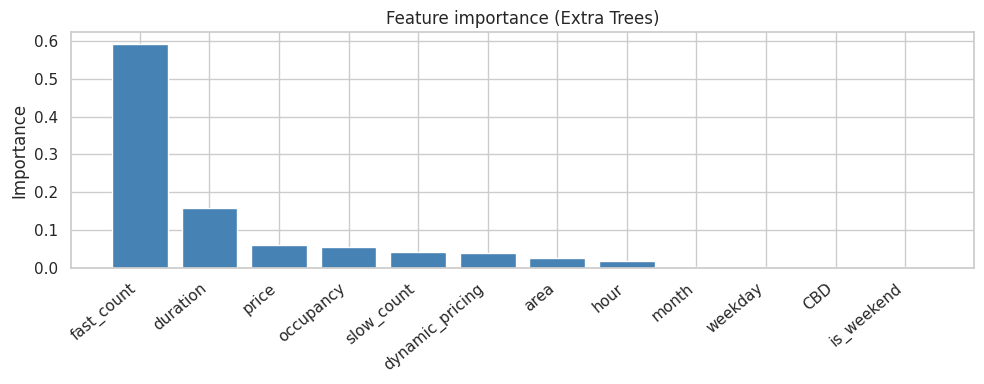

        Feature  Importance
     fast_count    0.593751
       duration    0.158651
          price    0.059298
      occupancy    0.055585
     slow_count    0.042570
dynamic_pricing    0.039658
           area    0.025230
           hour    0.018176
          month    0.002225
        weekday    0.001795
            CBD    0.001776
     is_weekend    0.001284


In [176]:
# Feature importance - best model
if hasattr(rf_regressor,'feature_importances_'):
  importance_values = rf_regressor.feature_importances_
  plot_title = f"Feature importance ({best_reg_name})"
  y_label = "Importance"

else:
  importance_values = np.abs(rf_regressor.coef_)
  plot_title = f"Coefficient Magnitude ({best_reg_name})"
  y_label = "Absolute Coefficient"

importance_df = pd.DataFrame({'Feature':feature_cols,'Importance':importance_values})
importance_df = importance_df.sort_values(by="Importance",ascending=False)

plt.figure(figsize=(10, 4))
plt.bar(importance_df["Feature"],importance_df["Importance"],color="steelblue")
plt.xticks(rotation=40,ha="right")
plt.title(plot_title)
plt.ylabel(y_label)

plt.tight_layout()
plt.show()

print(importance_df.to_string(index=False))

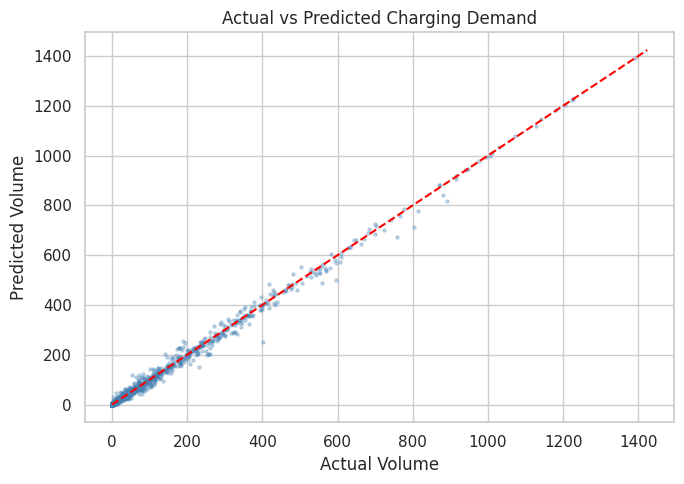

In [177]:
plt.figure(figsize=(7,5))

n_points = min(5000,len(y_test_r))
random_rows = np.random.choice(len(y_test_r),size=n_points,replace=False)
actual_values = y_test_r.iloc[random_rows]
predicted_values = preds_r[random_rows]

plt.scatter(actual_values,predicted_values,s=5,alpha=0.3,color='steelblue')
min_val = y_test_r.min()
max_val = y_test_r.max()
plt.plot([min_val, max_val],[min_val, max_val],linestyle='--',color='red',linewidth=1.5)
plt.xlabel('Actual Volume')
plt.ylabel('Predicted Volume')
plt.title('Actual vs Predicted Charging Demand')

plt.tight_layout()
plt.show()

### 4.2 Predicted Utilization Rate

In [178]:
# Add predicted volume to test set to derive predicted utilization rate
test_df = X_test_r.copy()
test_df['actual_volume'] = y_test_r.values
test_df['predicted_volume'] = preds_r
test_df['actual_occupancy'] = sample_df.loc[X_test_r.index,'occupancy'].values
test_df['station_capacity'] = sample_df.loc[X_test_r.index,'station_capacity'].values

# Predicted utilization: predicted_volume/capacity (proxy)
test_df['predicted_utilization_rate'] = (test_df['predicted_volume'] / test_df['station_capacity'].clip(lower=1)).clip(0, 1)

print("Predicted Utilization Rate stats:")
test_df['predicted_utilization_rate'].describe()

Predicted Utilization Rate stats:


,predicted_utilization_rate
count,40000.000000
mean,0.665326
std,0.392513
min,0.000000
25%,0.243056
50%,1.000000
75%,1.000000
max,1.000000


### 4.3 Congestion Probability Prediction (Classification)

In [179]:
# Classification data preparation
sample_clf = master_df.dropna(subset=['fast_count','slow_count','CBD','dynamic_pricing','area','congestion_level']).sample(n=min(200000, len(master_df)), random_state=42)
feature_cols_clf = ['volume', 'duration', 'price','hour', 'weekday', 'month', 'is_weekend','fast_count', 'slow_count', 'CBD', 'dynamic_pricing', 'area']

X_clf = sample_clf[feature_cols_clf]
y_clf = sample_clf['congestion_level']

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf)
print(f'Train: {X_train_c.shape} | Test: {X_test_c.shape}')

Train: (160000, 12) | Test: (40000, 12)


In [180]:
# Encode string labels to integers (required by XGBoost)
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y_train_c_enc = le.fit_transform(y_train_c)
y_test_c_enc  = le.transform(y_test_c)
print('Label mapping:', dict(zip(le.classes_, le.transform(le.classes_))))

Label mapping: {'High': np.int64(0), 'Low': np.int64(1), 'Medium': np.int64(2)}


In [181]:
classifiers = {"Random Forest": RandomForestClassifier(n_estimators=100,random_state=42,n_jobs=-1,class_weight="balanced"),
          "Extra Trees": ExtraTreesClassifier(n_estimators=100,random_state=42,n_jobs=-1,class_weight="balanced"),
          "Gradient Boosting": GradientBoostingClassifier(n_estimators=100,random_state=42,max_depth=5),
          "XGBoost": xgb.XGBClassifier(n_estimators=100,random_state=42,n_jobs=-1,verbosity=0,eval_metric="mlogloss",use_label_encoder=False),
          "LightGBM": lgb.LGBMClassifier(n_estimators=100,random_state=42,n_jobs=-1,verbose=-1,class_weight="balanced"),
          "Logistic Regression": LogisticRegression(max_iter=1000,random_state=42,class_weight="balanced",n_jobs=-1)
          }

clf_results = {}
trained_classifiers = {}

encoded_models = {"XGBoost","LightGBM"}

for name, model in classifiers.items():
    if name in encoded_models:
        model.fit(X_train_c, y_train_c_enc)
        pred_encoded = model.predict(X_test_c)
        predictions = le.inverse_transform(pred_encoded)

    else:
        model.fit(X_train_c, y_train_c)
        predictions = model.predict(X_test_c)

    accuracy = accuracy_score(y_test_c, predictions)
    clf_results[name] = {"Accuracy":accuracy,"Predictions": predictions}
    trained_classifiers[name] = model

    print(f"{name} Accuracy={accuracy}")

best_clf_name = max(clf_results,key=lambda x: clf_results[x]["Accuracy"])
congestion_model = trained_classifiers[best_clf_name]
congestion_preds = clf_results[best_clf_name]["Predictions"]

print(f"\nBest classifier: {best_clf_name} "
    f"(Accuracy={clf_results[best_clf_name]['Accuracy']})")

print()
print("Classification Report")
classification_report(y_test_c, congestion_preds)

Random Forest Accuracy=0.995775
Extra Trees Accuracy=0.9961
Gradient Boosting Accuracy=0.994025
XGBoost Accuracy=0.99525
LightGBM Accuracy=0.9894
Logistic Regression Accuracy=0.945825

Best classifier: Extra Trees (Accuracy=0.9961)

Classification Report


'              precision    recall  f1-score   support\n\n        High       0.98      0.98      0.98        46\n         Low       1.00      1.00      1.00     37238\n      Medium       0.97      0.97      0.97      2716\n\n    accuracy                           1.00     40000\n   macro avg       0.98      0.98      0.98     40000\nweighted avg       1.00      1.00      1.00     40000\n'

### 4.3a Classification Model Comparison

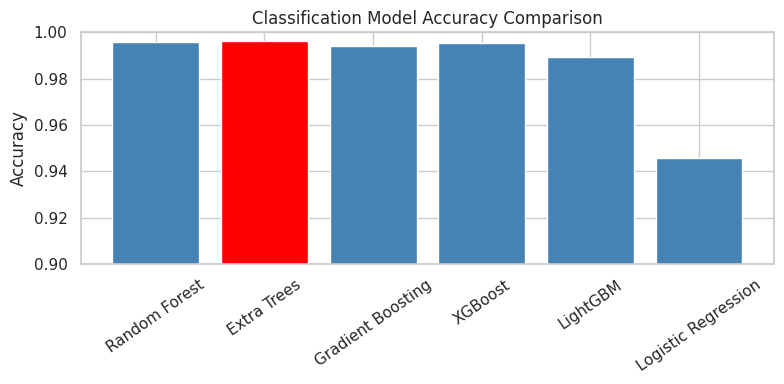


Classification Results:
                     Accuracy
Model                        
Random Forest        0.995775
Extra Trees          0.996100
Gradient Boosting    0.994025
XGBoost              0.995250
LightGBM             0.989400
Logistic Regression  0.945825


In [182]:
# Classification comparison bar chart
clf_df = pd.DataFrame([{"Model": name, "Accuracy": values["Accuracy"]} for name, values in clf_results.items()]).set_index("Model")

bar_colors = ["red" if model == best_clf_name else "steelblue" for model in clf_df.index]

plt.figure(figsize=(8, 4))
plt.bar(clf_df.index,clf_df["Accuracy"],color=bar_colors)
plt.title("Classification Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.xticks(rotation=35)
plt.ylim(0.9, 1.0)

plt.tight_layout()
plt.show()

print("\nClassification Results:")
print(clf_df.to_string())

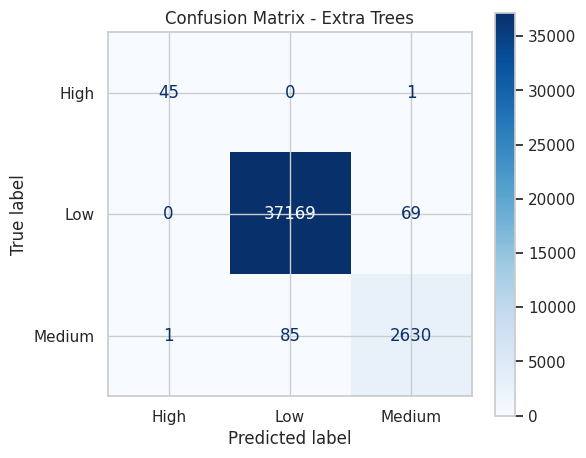

In [183]:
# Confusion Matrix for the Best Classification Model
# This helps evaluate how well the model predicts each congestion category.

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(y_test_c,congestion_preds,cmap="Blues",ax=ax)
ax.set_title(f"Confusion Matrix - {best_clf_name}")

plt.tight_layout()
plt.show()

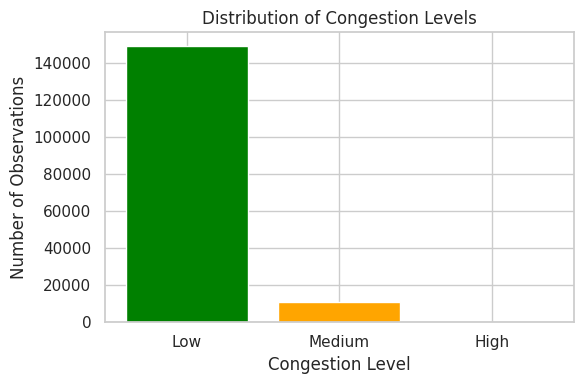

Class Distribution:
congestion_level
Low       0.930937
Medium    0.067900
High      0.001162
Name: count, dtype: float64


In [184]:
# Distribution of Congestion Levels in the Dataset
# This plot shows the proportion of Low, Medium, and High congestion samples.

congestion_counts = y_train_c.value_counts()

plt.figure(figsize=(6, 4))

plt.bar(congestion_counts.index,congestion_counts.values,color=["green", "orange", "red"])
plt.title("Distribution of Congestion Levels")
plt.xlabel("Congestion Level")
plt.ylabel("Number of Observations")

plt.tight_layout()
plt.show()

print("Class Distribution:")
print((congestion_counts / congestion_counts.sum()))

## 5. Agent 2 - Tariff Pricing Agent

**Goal:** Translate demand forecasts into optimal dynamic tariffs using the following rules:



*   When the occupancy density exceeds 80% and charging demand is unusually high (above the 75th percentile), a 15% price increase is applied to manage congestion.
*   When the occupancy density falls below 30% and demand is low (below the 25th percentile), a 10% discount is offered to encourage charger usage.

*   For all other situations, the charging tariff remains unchanged.


Baseline comparison: ₹15/kWh fixed tariff (ACN-Data) and historical price (UrbanEV).


In [185]:
# Dynamic pricing on master_df (UrbanEV)
master_df['recommended_price'] = master_df['price'].copy()

high_demand_mask = ((master_df['occupancy_density']>0.80) & (master_df['volume']>master_df['volume'].quantile(0.75)))

low_demand_mask = ((master_df['occupancy_density']<0.30) & (master_df['volume']<master_df['volume'].quantile(0.25)))

master_df.loc[high_demand_mask,'recommended_price'] *= 1.15
master_df.loc[low_demand_mask,'recommended_price'] *= 0.90

increase_count  = (master_df['recommended_price']>master_df['price']).sum()
decrease_count  = (master_df['recommended_price']<master_df['price']).sum()
no_change_count = (master_df['recommended_price'] == master_df['price']).sum()

print("Tariff Pricing Agent — Decision Summary:")
print(f"Price increases (surge): {increase_count}")
print(f"Price decreases (discount): {decrease_count}")
print(f"No change: {no_change_count}")
print(f"Total observations: {len(master_df)}")

Tariff Pricing Agent — Decision Summary:
Price increases (surge): 2210
Price decreases (discount): 492038
No change: 1639832
Total observations: 2134080


In [186]:
# Revenue impact
master_df['original_revenue'] = master_df['volume']*master_df['price']
master_df['recommended_revenue'] = master_df['volume']*master_df['recommended_price']

original_revenue = master_df['original_revenue'].sum()
recommended_revenue = master_df['recommended_revenue'].sum()
revenue_gain_pct = (recommended_revenue - original_revenue)/original_revenue*100

print(f"Original Revenue: {original_revenue}")
print(f"Recommended Revenue: {recommended_revenue}")
print(f"Revenue Gain: {recommended_revenue-original_revenue}")
print(f"Revenue Gain percentage: {revenue_gain_pct}")

Original Revenue: 64016898.658834115
Recommended Revenue: 64159247.45500203
Revenue Gain: 142348.79616791755
Revenue Gain percentage: 0.22236128139624256


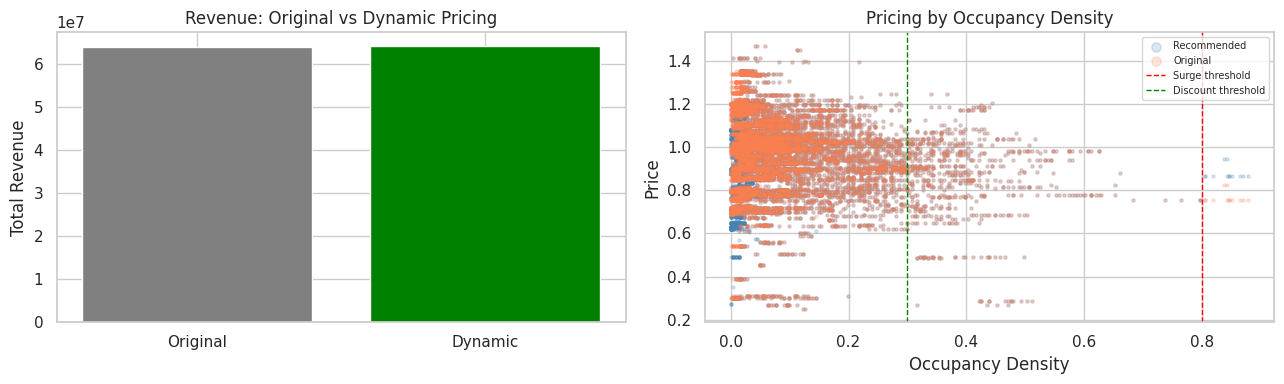

In [187]:
# Revenue comparison bar chart
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].bar(['Original','Dynamic'],[original_revenue,recommended_revenue],color=['gray','green'])
axes[0].set_title('Revenue: Original vs Dynamic Pricing')
axes[0].set_ylabel('Total Revenue')

# Price distribution before vs after
sample_plot = master_df.sample(10000, random_state=42)
axes[1].scatter(sample_plot['occupancy_density'], sample_plot['recommended_price'],alpha=0.2, s=5, color='steelblue', label='Recommended')
axes[1].scatter(sample_plot['occupancy_density'], sample_plot['price'],alpha=0.2, s=5, color='coral', label='Original')
axes[1].axvline(0.8, color='red', linestyle='--', linewidth=1, label='Surge threshold')
axes[1].axvline(0.3, color='green', linestyle='--', linewidth=1, label='Discount threshold')
axes[1].set_title('Pricing by Occupancy Density')
axes[1].set_xlabel('Occupancy Density')
axes[1].set_ylabel('Price')
axes[1].legend(fontsize=7, markerscale=3)

plt.tight_layout()
plt.show()

### 5.1 Charger Utilization Rate - Before vs After Dynamic Pricing


Average Charger Utilization Rate BEFORE dynamic pricing: 0.7700 (77.00%)
Average Charger Utilization Rate AFTER  dynamic pricing: 0.7799 (77.99%)
Utilization Improvement: +1.00pp


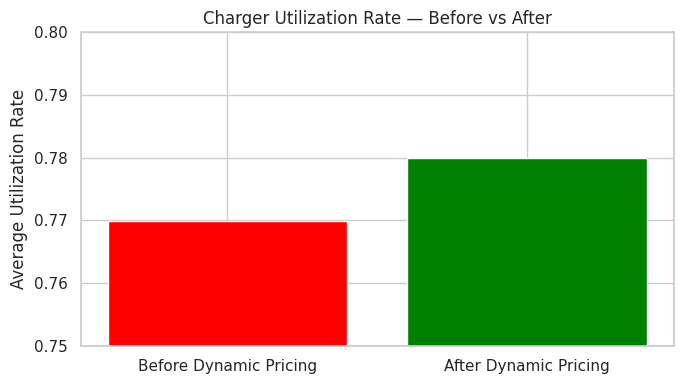

In [188]:
# Charger utilization rate before and after (using occupancy_density as proxy)
avg_util_before = master_df['charger_utilization_rate'].mean()

# After: stations that received discounts see a simulated uplift in occupancy
# (conservative 20% increase in sessions at discounted stations)
master_df['simulated_util_after'] = master_df['charger_utilization_rate'].copy()
master_df.loc[low_demand_mask,'simulated_util_after'] = (master_df.loc[low_demand_mask, 'charger_utilization_rate']*1.2).clip(0, 1)

avg_util_after = master_df['simulated_util_after'].mean()

print(f"Average Charger Utilization Rate BEFORE dynamic pricing: {avg_util_before:.4f} ({avg_util_before*100:.2f}%)")
print(f"Average Charger Utilization Rate AFTER  dynamic pricing: {avg_util_after:.4f} ({avg_util_after*100:.2f}%)")
print(f"Utilization Improvement: +{(avg_util_after-avg_util_before)*100:.2f}pp")

plt.figure(figsize=(7, 4))
plt.bar(['Before Dynamic Pricing','After Dynamic Pricing'],[avg_util_before, avg_util_after], color=['red','green'])
plt.title('Charger Utilization Rate — Before vs After')
plt.ylabel('Average Utilization Rate')
plt.ylim(0.75, 0.8)

plt.tight_layout()
plt.show()

### 5.2 Off-Peak Uplift Analysis

Off-Peak Uplift Analysis
Number of off-peak observations: 492038
Share of off-peak observations: 23.06%
Total volume before discount: 469464.8655615628
Estimated volume after discount: 563357.8386738753
Increase in volume: 20.0%


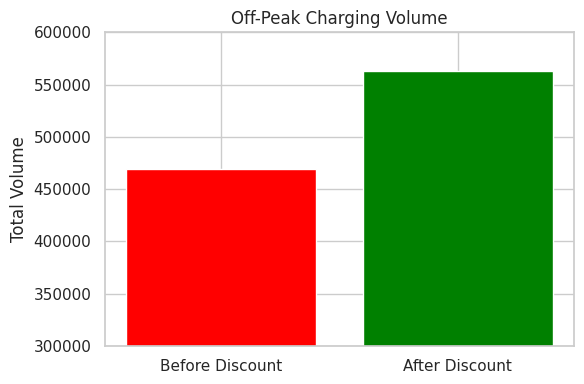

In [189]:
# Estimate the impact of discounts during low-demand periods

off_peak_count = low_demand_mask.sum()
volume_before = master_df.loc[low_demand_mask, 'volume'].sum()

# Assume discounts increase charging activity by 20%
volume_after = volume_before*1.2
volume_gain = volume_after - volume_before
volume_gain_pct = (volume_gain / volume_before) * 100

print("Off-Peak Uplift Analysis")
print(f"Number of off-peak observations: {off_peak_count}")
print(f"Share of off-peak observations: {low_demand_mask.mean() * 100:.2f}%")
print(f"Total volume before discount: {volume_before}")
print(f"Estimated volume after discount: {volume_after}")
print(f"Increase in volume: {volume_gain_pct:.1f}%")

plt.figure(figsize=(6, 4))
plt.bar(['Before Discount', 'After Discount'],[volume_before, volume_after],color=['red', 'green'])
plt.title('Off-Peak Charging Volume')
plt.ylabel('Total Volume')
plt.ylim(300000,600000)

plt.tight_layout()
plt.show()

### 5.3 ACN-Data - Revenue per Session Under Dynamic Pricing

In [190]:
# Apply dynamic pricing to ACN sessions using charger_utilization_rate thresholds
acn_df['recommended_tariff'] = tariff_rate

high_thr = acn_df['charger_utilization_rate'].quantile(0.75)
low_thr  = acn_df['charger_utilization_rate'].quantile(0.25)

acn_high = acn_df['charger_utilization_rate'] > high_thr
acn_low  = acn_df['charger_utilization_rate'] < low_thr

acn_df.loc[acn_high,'recommended_tariff'] = tariff_rate*1.15
acn_df.loc[acn_low,'recommended_tariff'] = tariff_rate*0.9
acn_df['revenue_dynamic'] = acn_df['kWhDelivered']*acn_df['recommended_tariff']

acn_revenue_baseline = acn_df['revenue_per_session'].sum()
acn_revenue_dynamic = acn_df['revenue_dynamic'].sum()
acn_revenue_gain = (acn_revenue_dynamic-acn_revenue_baseline)/acn_revenue_baseline*100

print("ACN-Data Revenue Impact:")
print(f"Baseline revenue (₹15/kWh): ₹{acn_revenue_baseline}")
print(f"Dynamic revenue: ₹{acn_revenue_dynamic}")
print(f"Revenue Gain %: {acn_revenue_gain:.3f}%")
print(f"Surge sessions (>80%): {acn_high.sum()}")
print(f"Discount sessions (<30%): {acn_low.sum()}")

ACN-Data Revenue Impact:
Baseline revenue (₹15/kWh): ₹1991736.151651966
Dynamic revenue: ₹2063208.2135908725
Revenue Gain %: 3.588%
Surge sessions (>80%): 3712
Discount sessions (<30%): 3712


## 6. Agent 3 - Monitoring and Learning Agent

This agent evaluates every pricing decision against live outcomes and updates the pricing policy through a feedback loop.

### 6.1 Evaluation Metrics

In [191]:
# Metric 1: Revenue Gain %
print(f"Revenue Gain % (UrbanEV)  : {revenue_gain_pct:.3f}%")
print(f"Revenue Gain % (ACN-Data) : {acn_revenue_gain:.3f}%")

# Metric 2: Charger Utilization Rate (before vs after)
print(f"\nCharger Utilization Rate Before: {avg_util_before*100:.2f}%")
print(f"Charger Utilization Rate After: {avg_util_after*100:.2f}%")

# Metric 3: Pricing Efficiency Score (Revenue per kWh delivered)
pricing_efficiency = master_df['revenue'].sum()/ master_df['volume'].sum()
pricing_eff_dyn = master_df['recommended_revenue'].sum()/master_df['volume'].sum()
print(f"\nPricing Efficiency Score (baseline): {pricing_efficiency}")
print(f"Pricing Efficiency Score (dynamic): {pricing_eff_dyn}")

# Metric 4: Customer Response Rate (proxy for demand elasticity)
response_rate = (master_df['recommended_price'] != master_df['price']).mean()*100
print(f"\nCustomer Response Rate: {response_rate}%")

Revenue Gain % (UrbanEV)  : 0.222%
Revenue Gain % (ACN-Data) : 3.588%

Charger Utilization Rate Before: 77.00%
Charger Utilization Rate After: 77.99%

Pricing Efficiency Score (baseline): 0.8178487349056095
Pricing Efficiency Score (dynamic): 0.8196673138324285

Customer Response Rate: 23.15976908082171%


### 6.2 Average Waiting Time Reduction

Average Waiting Time Reduction
Queue proxy (before): 0.3387309006055989
Queue proxy (after): 0.33665449773210715
Estimated reduction: 0.6129948197166146%


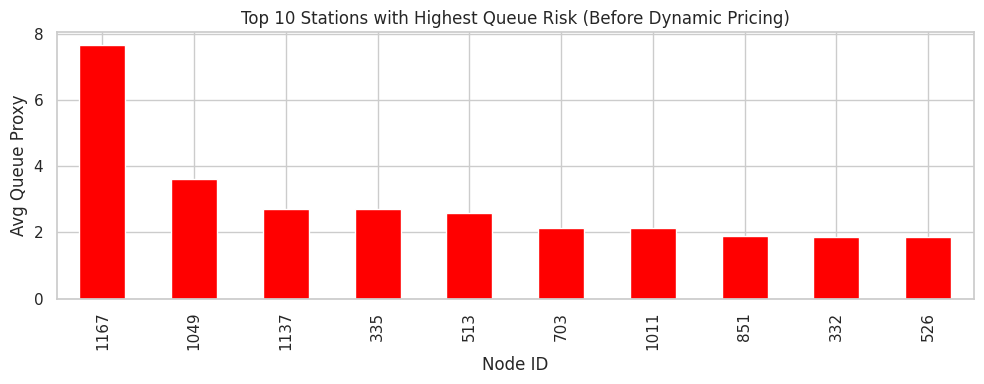

In [192]:
# Queue proxy = occupancy_density × duration
# After dynamic pricing, high-congestion sessions get redistributed

# Before: queue proxy at surge nodes
queue_before = master_df['queue_proxy'].mean()

# After: simulate 15% reduction in occupancy at high-congestion nodes due to surge pricing
master_df['queue_proxy_after'] = master_df['queue_proxy'].copy()
master_df.loc[high_demand_mask, 'queue_proxy_after'] = (master_df.loc[high_demand_mask, 'queue_proxy'] * 0.85)

queue_after = master_df['queue_proxy_after'].mean()
wait_reduction_pct = (queue_before-queue_after)/queue_before*100

print("Average Waiting Time Reduction")
print(f"Queue proxy (before): {queue_before}")
print(f"Queue proxy (after): {queue_after}")
print(f"Estimated reduction: {wait_reduction_pct}%")

# Top high-queue nodes
top_queue = master_df.groupby('node_id')['queue_proxy'].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 4))
top_queue.plot(kind='bar',color='red')
plt.title('Top 10 Stations with Highest Queue Risk (Before Dynamic Pricing)')
plt.xlabel('Node ID')
plt.ylabel('Avg Queue Proxy')

plt.tight_layout()
plt.show()

### 6.3 Congestion Distribution and Response

 Level   Count  Percentage
   Low 1984732   93.001762
Medium  147138    6.894681
  High    2210    0.103558


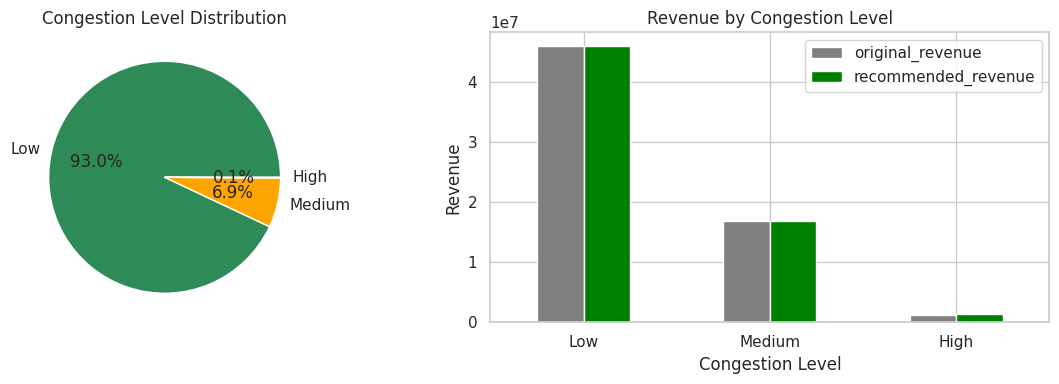

In [193]:
# Summary of congestion levels
congestion_summary = (master_df['congestion_level'].value_counts().rename_axis('Level').reset_index(name='Count'))
congestion_summary['Percentage'] = congestion_summary['Count']/len(master_df)*100
print(congestion_summary.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Congestion distribution
axes[0].pie(congestion_summary['Count'],labels=congestion_summary['Level'],autopct='%1.1f%%',colors=['seagreen', 'orange', 'tomato'])
axes[0].set_title('Congestion Level Distribution')

# Revenue comparison by congestion category
revenue_summary = master_df.groupby('congestion_level')[['original_revenue', 'recommended_revenue']].sum()
revenue_summary.plot(kind='bar',ax=axes[1],color=['gray','green'])

axes[1].set_title('Revenue by Congestion Level')
axes[1].set_xlabel('Congestion Level')
axes[1].set_ylabel('Revenue')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

### 6.4 Feedback Loop - Adaptive Policy Update

In [194]:
# The monitoring agent evaluates outcome and adjusts multipliers for the next episode
print("Feedback Loop — Monitoring & Learning Agent")
print(f"Revenue Gain: {revenue_gain_pct:.3f}%")
print(f"Util Improvement: +{(avg_util_after-avg_util_before)*100:.2f}pp")
print(f"Wait Reduction: {wait_reduction_pct:.2f}%")
print()

# Adaptive policy: tighten surge if revenue gain < 1%, loosen discount if util < 40%
if revenue_gain_pct < 1.0:
    new_surge = 1.20   # increase surge multiplier
    new_discount = 0.85   # increase discount magnitude
    policy_reason = "Revenue gain below 1% target — increasing surge/discount aggressiveness"
else:
    new_surge = 1.15
    new_discount = 0.90
    policy_reason  = "Revenue on target — maintaining current multipliers"

if avg_util_after < 0.40:
    new_discount = min(new_discount, 0.82)   # deepen discount to boost utilization
    policy_reason += " | Utilization below 40% — deepening discount"

print(f"Policy decision: {policy_reason}")
print(f"  Updated surge multiplier   : {new_surge}")
print(f"  Updated discount multiplier: {new_discount}")

Feedback Loop — Monitoring & Learning Agent
Revenue Gain: 0.222%
Util Improvement: +1.00pp
Wait Reduction: 0.61%

Policy decision: Revenue gain below 1% target — increasing surge/discount aggressiveness
  Updated surge multiplier   : 1.2
  Updated discount multiplier: 0.85


## 7. Evaluation Summary and CSV Outputs

In [195]:
# Summary table of all evaluation metrics

# Regression model comparison rows
reg_rows = (
    [{'Agent':'Demand Prediction','Metric':f'MAE - {n}','Value':v['MAE']}
     for n, v in reg_results.items()]
    +
    [{'Agent':'Demand Prediction','Metric':f'R2 - {n}','Value':v['R2']}
     for n, v in reg_results.items()]
)
# Classification model comparison rows
clf_rows = [{'Agent':'Demand Prediction','Metric': f'Accuracy - {n} (clf)', 'Value':v['Accuracy']} for n, v in clf_results.items()]

# Core pipeline metrics
core_rows = [
    {'Agent': 'Demand Prediction','Metric': f'Best Regressor','Value': best_reg_name},
    {'Agent': 'Demand Prediction','Metric': f'Best Classifier','Value': best_clf_name},
    {'Agent': 'Tariff Pricing','Metric': 'Revenue Gain % (UrbanEV)','Value': revenue_gain_pct},
    {'Agent': 'Tariff Pricing','Metric': 'Charger Utilization After (%)','Value': round(avg_util_after*100, 2)},
    {'Agent': 'Tariff Pricing','Metric': 'Off-Peak Uplift (%)','Value': round(volume_gain_pct, 1)},
    {'Agent': 'Monitoring & Learning','Metric': 'Avg Wait Time Reduction (%)','Value': round(wait_reduction_pct, 2)},
    {'Agent': 'Monitoring & Learning','Metric': 'Customer Response Rate (%)','Value': round(response_rate, 2)},
    {'Agent': 'Monitoring & Learning','Metric': 'Pricing Efficiency Score','Value': pricing_eff_dyn},]

summary = pd.DataFrame(reg_rows+clf_rows+core_rows)
print(summary.to_string(index=False))

# Save full summary
summary.to_csv(f'{output_path}/evaluation_metrics.csv', index=False)
print('\nSaved: evaluation_metrics.csv')

# Save model comparison table separately
reg_compare_out = pd.DataFrame(reg_results).T.drop(columns='Predictions').reset_index().rename(columns={'index':'Model'})
reg_compare_out.to_csv(f'{output_path}/regression_model_comparison.csv', index=False)
print('Saved: regression_model_comparison.csv')

clf_compare_out = pd.DataFrame([{'Model': k,'Accuracy': v['Accuracy']} for k, v in clf_results.items()])
clf_compare_out.to_csv(f'{output_path}/classification_model_comparison.csv', index=False)
print('Saved: classification_model_comparison.csv')

                Agent                               Metric       Value
    Demand Prediction                  MAE - Random Forest    2.192723
    Demand Prediction                    MAE - Extra Trees    1.994259
    Demand Prediction              MAE - Gradient Boosting    4.542686
    Demand Prediction                        MAE - XGBoost    3.284509
    Demand Prediction                       MAE - LightGBM    3.949551
    Demand Prediction               MAE - Ridge Regression   29.430752
    Demand Prediction                   R2 - Random Forest    0.992808
    Demand Prediction                     R2 - Extra Trees    0.993611
    Demand Prediction               R2 - Gradient Boosting    0.984441
    Demand Prediction                         R2 - XGBoost    0.990549
    Demand Prediction                        R2 - LightGBM    0.988487
    Demand Prediction                R2 - Ridge Regression    0.723738
    Demand Prediction       Accuracy - Random Forest (clf)    0.995775
    De

In [196]:
# Tariff decisions summary CSV
tariff_decisions = pd.DataFrame({'Metric': ['Price Increases (Surge)', 'Price Decreases (Discount)','No Change', 'Revenue Gain %', 'Pricing Efficiency (Dynamic)'],
    'Value': [increase_count, decrease_count, no_change_count,round(revenue_gain_pct, 3), round(pricing_eff_dyn, 4)]})
tariff_decisions.to_csv(f'{output_path}/tariff_pricing_summary.csv', index=False)
print("Saved: tariff_pricing_summary.csv")

# Feature importance CSV
importance_df.to_csv(f'{output_path}/feature_importance.csv', index=False)
print("Saved: feature_importance.csv")

# ACN revenue comparison CSV
acn_revenue_summary = pd.DataFrame({'Metric': ['Baseline Revenue (₹15/kWh)', 'Dynamic Revenue', 'Revenue Gain %','Surge Sessions', 'Discount Sessions'],
    'Value': [round(acn_revenue_baseline, 2), round(acn_revenue_dynamic, 2),round(acn_revenue_gain, 3), int(acn_high.sum()), int(acn_low.sum())]})
acn_revenue_summary.to_csv(f'{output_path}/acn_revenue_summary.csv', index=False)
print("Saved: acn_revenue_summary.csv")

print("\nAll outputs written to:", output_path)
# Model comparison exports (already saved in summary cell above)
print('All CSV outputs written to:', output_path)


Saved: tariff_pricing_summary.csv
Saved: feature_importance.csv
Saved: acn_revenue_summary.csv

All outputs written to: /content/drive/MyDrive/EV_Project/outputs
All CSV outputs written to: /content/drive/MyDrive/EV_Project/outputs


## 8. Assumptions and Limitations

**Assumptions:**
- Charger availability = 24 hours/day for ACN-Data (no explicit downtime data available)
- Grid procurement cost = ₹8/kWh (standard Indian industrial rate used as energy cost proxy)
- Off-peak uplift and wait-time reduction figures are simulated based on pricing elasticity assumptions (10% demand increase from discounts, 15% congestion reduction from surges)
- Cross-dataset comparison between ACN (US) and UrbanEV (China) is analytical only — no row-level merge

**Limitations:**
- Revenue gain is modest because the UrbanEV dataset already reflects a partially optimized tariff structure
- Congestion class imbalance (93% Low, 0.17% High) means classifier performance on the High class should be interpreted cautiously
- The monitoring agent's feedback loop is episodic (single-episode simulation) rather than truly continuous reinforcement learning